In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import ast

pd.options.mode.copy_on_write = True

## Dataset Transformations and EDA

1. Listings
2. Reviews
3. Monuments
4. Concert Halls
5. University
6. Transport Centers
7. Metro

### 1. Listings

- Reduced size to meaningful columns
- Convert price column to float values
- Explored the value distribution of multiple variables to decide on visualization approaches
- Explored the locations of the Airbnbs to decide on visualization approaches

In [36]:
df_list = pd.read_csv('listings_complete.csv', float_precision='high')
df_list = df_list[['id', 'listing_url', 'host_id', 'host_since', 'host_response_time', 
                   'host_acceptance_rate', 'neighbourhood', 'latitude', 'longitude', 
                   'room_type', 'accommodates', 'bathrooms', 'beds', 'price', 
                   'number_of_reviews', 'first_review', 'review_scores_rating', 
                   'review_scores_accuracy', 'review_scores_cleanliness', 
                   'review_scores_checkin', 'review_scores_communication', 
                   'review_scores_location', 'review_scores_value', 'reviews_per_month']]
df_list['price'] = df_list['price'].str.replace('$', '', regex=False)\
                                   .str.replace(',', '', regex=False)\
                                   .astype(float)
df_list

,id,listing_url,host_id,host_since,host_response_time,host_acceptance_rate,neighbourhood,latitude,longitude,room_type,...,number_of_reviews,first_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,reviews_per_month
0,208147,https://www.airbnb.com/rooms/208147,1024383,2011-08-26,within an hour,100%,"Vila do Conde, Porto, Portugal",41.326347,-8.660382,Private room,...,61,2015-07-03,4.98,4.95,4.98,4.93,4.97,4.84,4.98,0.53
1,241573,https://www.airbnb.com/rooms/241573,1266562,2011-10-09,within an hour,100%,NaN,41.146870,-8.601730,Entire home/apt,...,224,2011-11-02,4.59,4.77,4.77,4.76,4.70,4.61,4.61,1.40
2,3902889,https://www.airbnb.com/rooms/3902889,4656501,2013-01-10,within an hour,100%,"Porto, Porto District, Portugal",41.146300,-8.599030,Entire home/apt,...,36,2014-09-14,4.78,4.81,4.72,4.72,4.69,4.64,4.58,0.29
3,3907554,https://www.airbnb.com/rooms/3907554,3367367,2012-08-25,within an hour,100%,"Porto, Porto District, Portugal",41.160630,-8.590560,Private room,...,301,2014-09-05,4.84,4.85,4.86,4.90,4.95,4.62,4.82,2.40
4,7918261,https://www.airbnb.com/rooms/7918261,40592098,2015-08-05,within an hour,69%,"Bonfim, Porto, Portugal",41.147030,-8.598040,Entire home/apt,...,11,2015-09-07,4.55,5.00,4.82,4.91,4.45,4.27,4.55,0.10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14427,1310341115130349886,https://www.airbnb.com/rooms/1310341115130349886,49819978,2015-11-24,within an hour,100%,NaN,41.151344,-8.618426,Entire home/apt,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14428,1310754582639827634,https://www.airbnb.com/rooms/1310754582639827634,666783631,2024-12-13,NaN,NaN,"Porto, Portugal",41.149146,-8.619346,Entire home/apt,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14429,1310854497620920328,https://www.airbnb.com/rooms/1310854497620920328,666806969,2024-12-13,NaN,NaN,"Porto, Portugal",41.145189,-8.620346,Entire home/apt,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14430,1310990289721497313,https://www.airbnb.com/rooms/1310990289721497313,30153947,2015-03-28,NaN,NaN,NaN,41.135156,-8.606841,Entire home/apt,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


count    12884.000000
mean         4.708875
std          0.341232
min          1.000000
25%          4.600000
50%          4.790000
75%          4.920000
max          5.000000
Name: review_scores_rating, dtype: float64


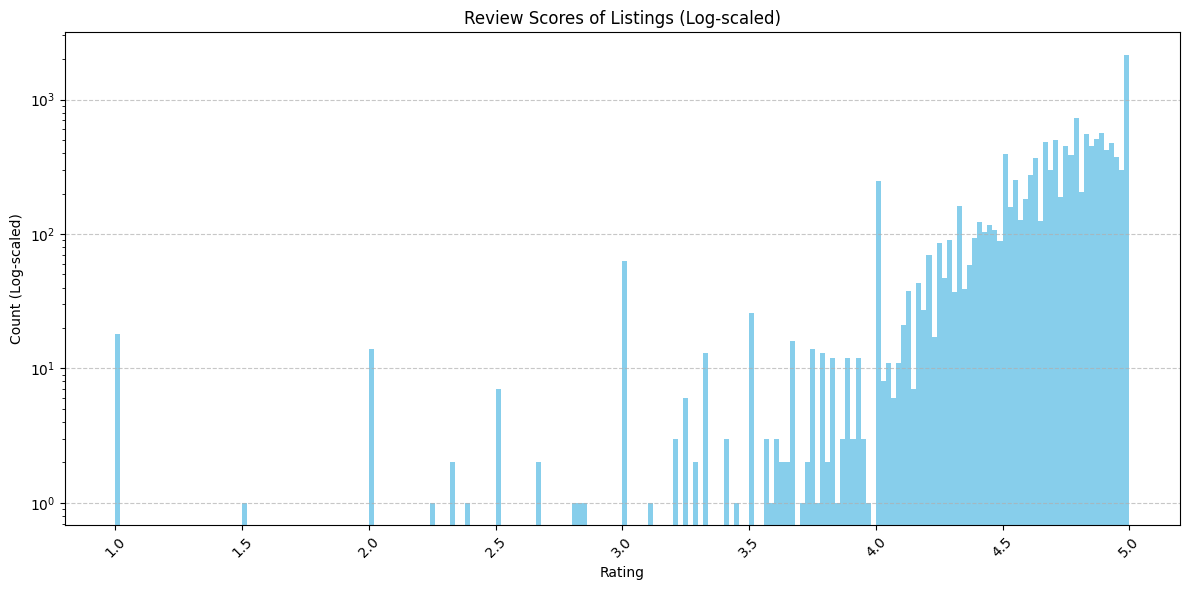

In [37]:
print(df_list['review_scores_rating'].describe())

plt.figure(figsize=(12, 6))
plt.hist(df_list['review_scores_rating'], color='skyblue', bins=200, log=True)
plt.title('Review Scores of Listings (Log-scaled)')
plt.xlabel('Rating')
plt.ylabel('Count (Log-scaled)')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

count    12678.000000
mean        87.081401
std        160.560696
min          9.000000
25%         47.000000
50%         65.000000
75%         93.000000
max       9999.000000
Name: price, dtype: float64


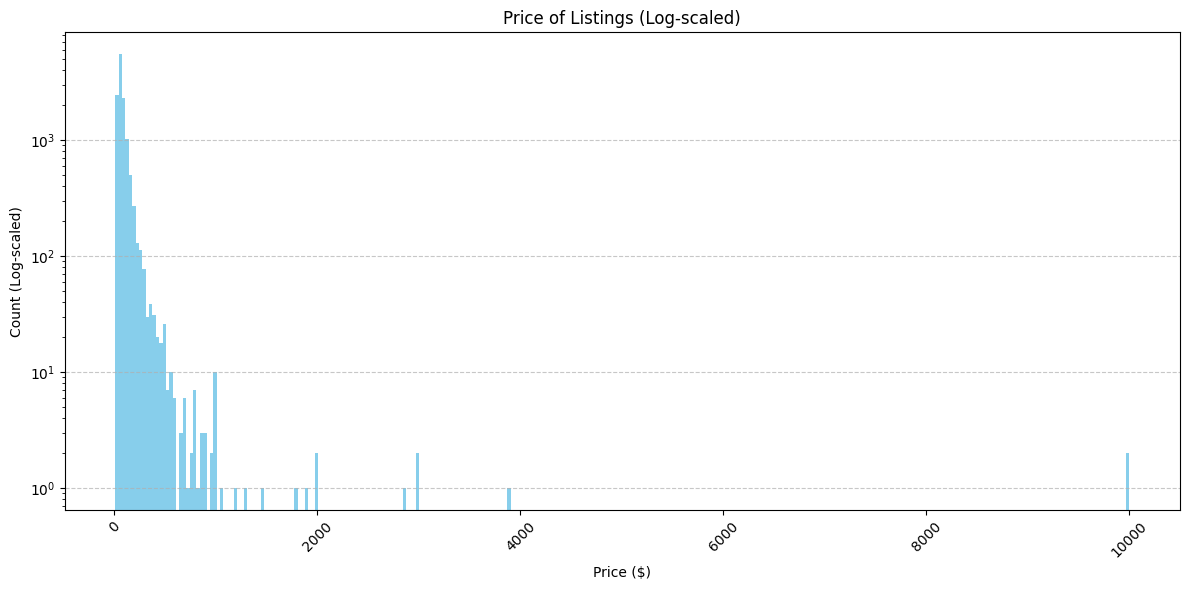

In [38]:
print(df_list['price'].describe())

plt.figure(figsize=(12, 6))
plt.hist(df_list['price'], color='skyblue', bins=300, log=True)
plt.title('Price of Listings (Log-scaled)')
plt.xlabel('Price ($)')
plt.ylabel('Count (Log-scaled)')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

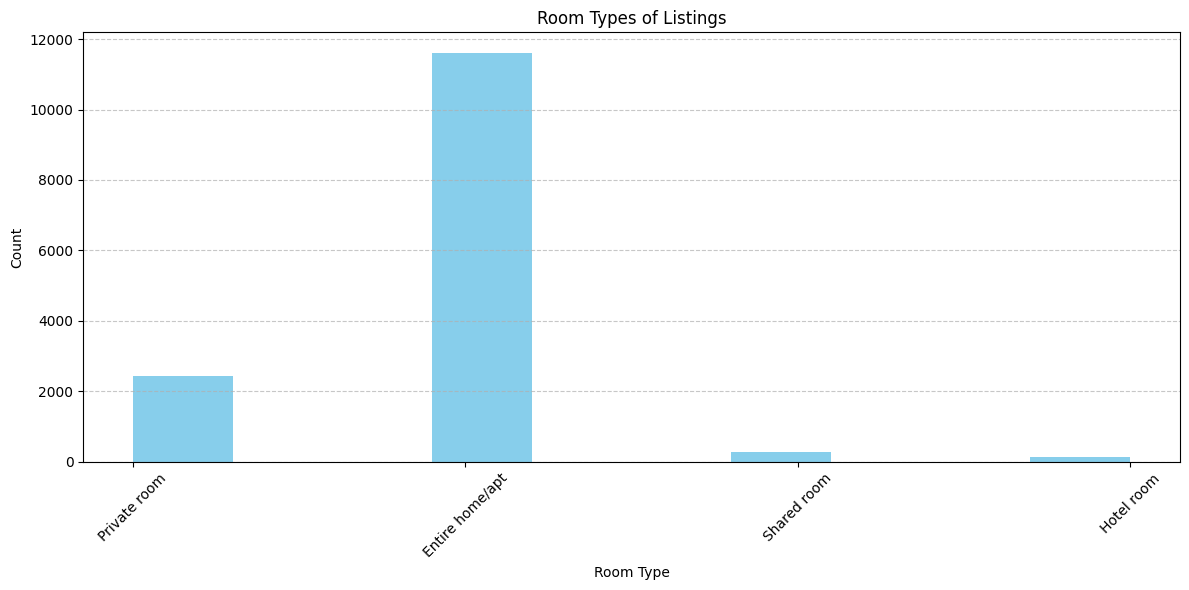

In [39]:
plt.figure(figsize=(12, 6))
plt.hist(df_list['room_type'], color='skyblue')
plt.title('Room Types of Listings')
plt.xlabel('Room Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

count    14432.000000
mean        65.499376
std         98.084608
min          0.000000
25%          4.000000
50%         25.000000
75%         85.250000
max        976.000000
Name: number_of_reviews, dtype: float64


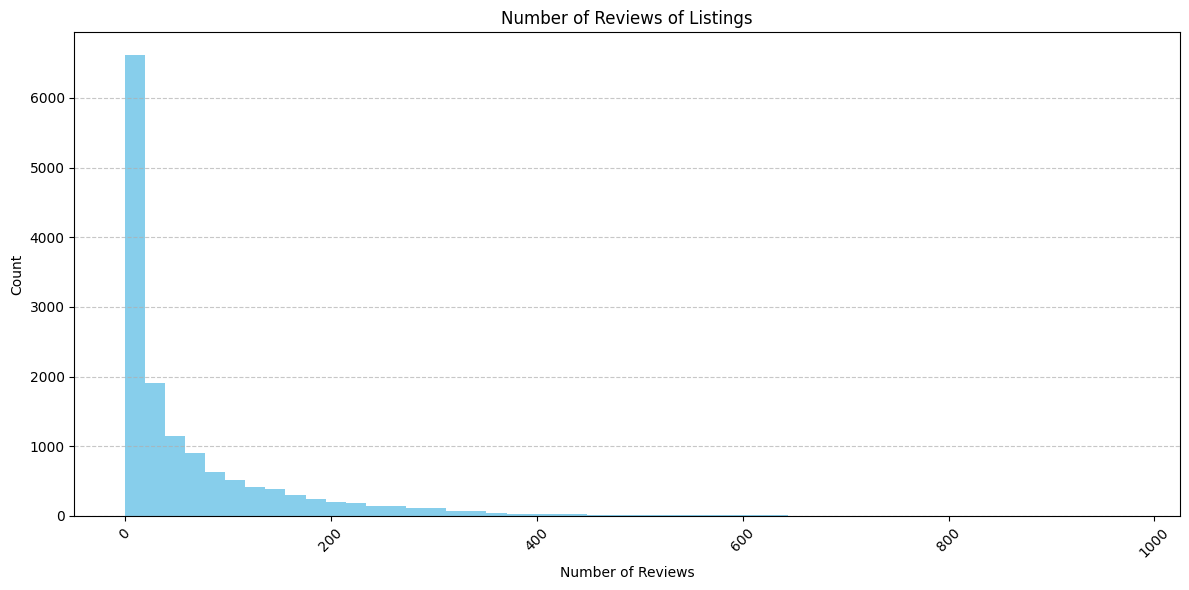

In [40]:
print(df_list['number_of_reviews'].dropna().describe())

plt.figure(figsize=(12, 6))
plt.hist(df_list['number_of_reviews'].dropna(), color='skyblue', bins=50)
plt.title('Number of Reviews of Listings')
plt.xlabel('Number of Reviews')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

count    12884.000000
mean         1.671353
std          1.610874
min          0.010000
25%          0.380000
50%          1.160000
75%          2.540000
max         16.430000
Name: reviews_per_month, dtype: float64


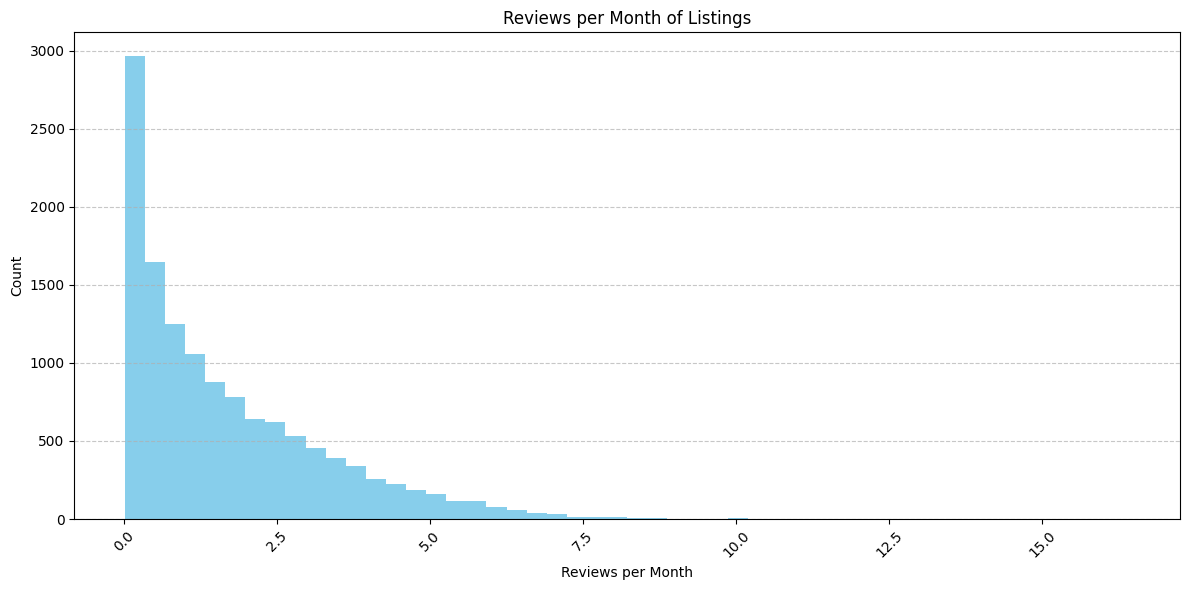

In [41]:
print(df_list['reviews_per_month'].dropna().describe())

plt.figure(figsize=(12, 6))
plt.hist(df_list['reviews_per_month'].dropna(), color='skyblue', bins=50)
plt.title('Reviews per Month of Listings')
plt.xlabel('Reviews per Month')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

count    12668.000000
mean         2.190638
std          1.715831
min          0.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         25.000000
Name: beds, dtype: float64


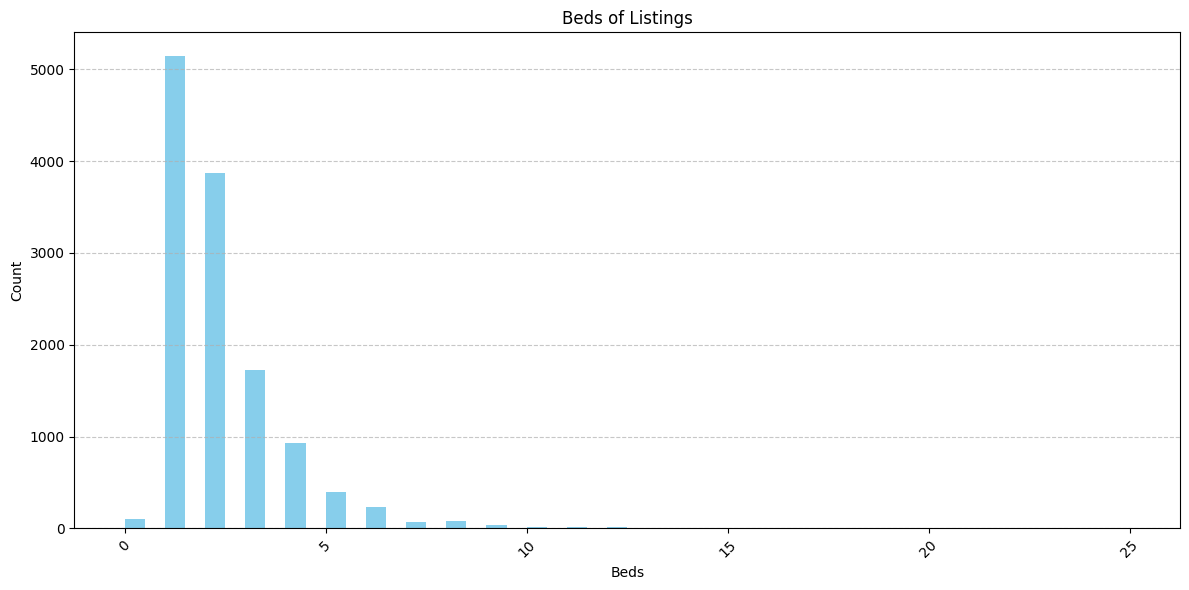

In [42]:
print(df_list['beds'].dropna().describe())

plt.figure(figsize=(12, 6))
plt.hist(df_list['beds'].dropna(), color='skyblue', bins=50)
plt.title('Beds of Listings')
plt.xlabel('Beds')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

count    12679.000000
mean         1.338355
std          0.802094
min          0.000000
25%          1.000000
50%          1.000000
75%          1.500000
max         20.000000
Name: bathrooms, dtype: float64


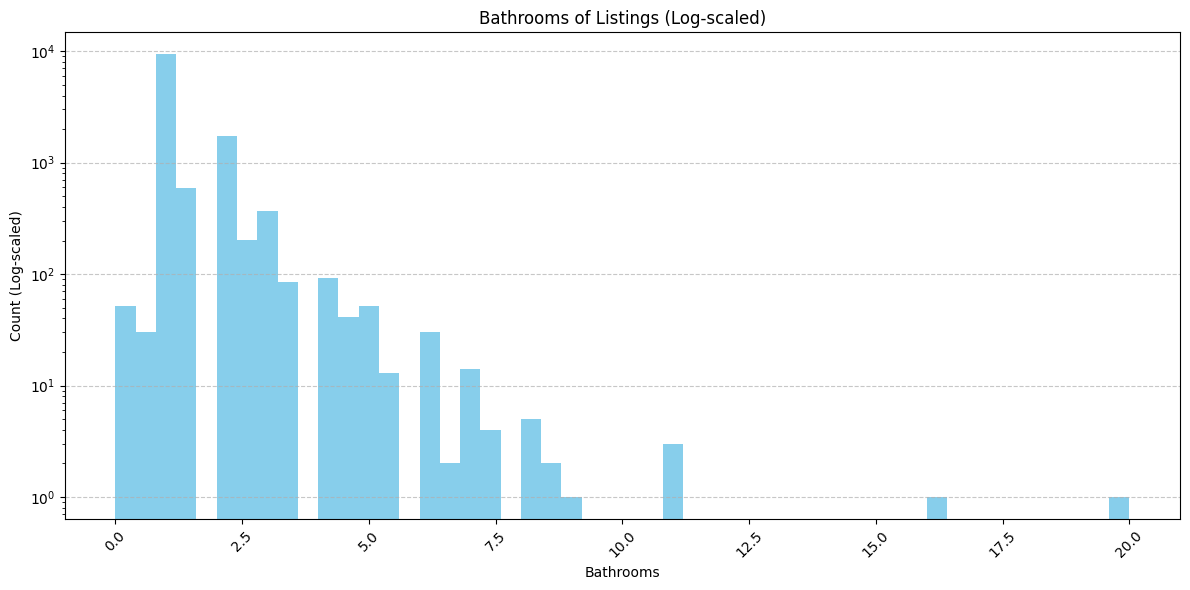

In [43]:
print(df_list['bathrooms'].dropna().describe())

plt.figure(figsize=(12, 6))
plt.hist(df_list['bathrooms'].dropna(), color='skyblue', bins=50, log=True)
plt.title('Bathrooms of Listings (Log-scaled)')
plt.xlabel('Bathrooms')
plt.ylabel('Count (Log-scaled)')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

count    14432.000000
mean         3.606777
std          2.137299
min          1.000000
25%          2.000000
50%          3.000000
75%          4.000000
max         16.000000
Name: accommodates, dtype: float64


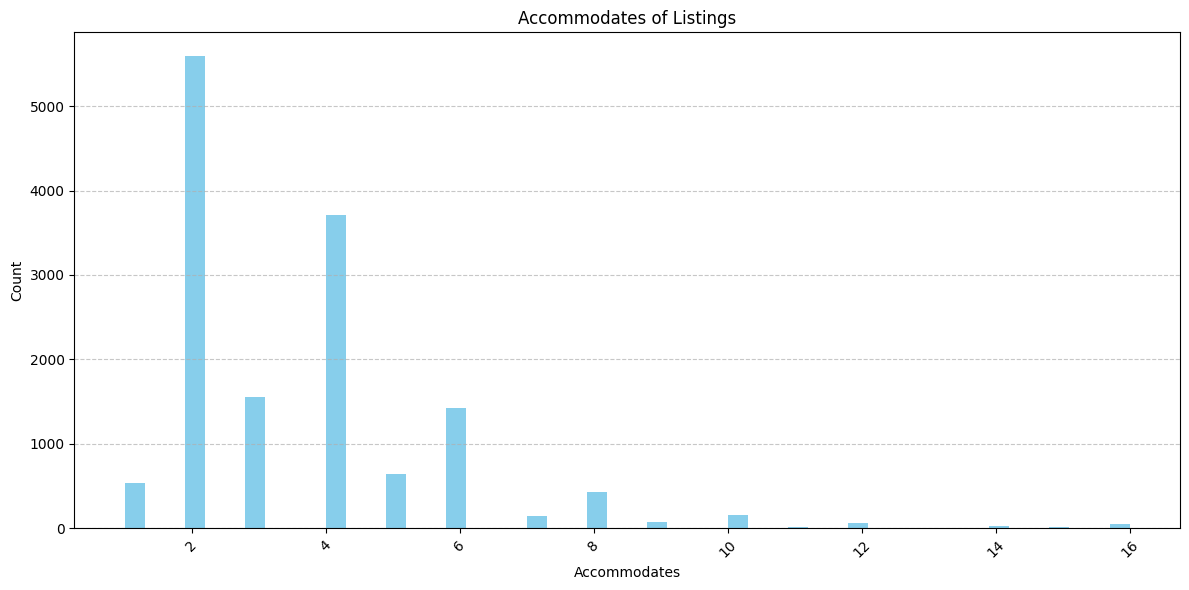

In [44]:
print(df_list['accommodates'].dropna().describe())

plt.figure(figsize=(12, 6))
plt.hist(df_list['accommodates'].dropna(), color='skyblue', bins=50)
plt.title('Accommodates of Listings')
plt.xlabel('Accommodates')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [45]:
fig = px.scatter_map(
    data_frame=df_list,
    lat='latitude',
    lon='longitude',
)

fig.show()

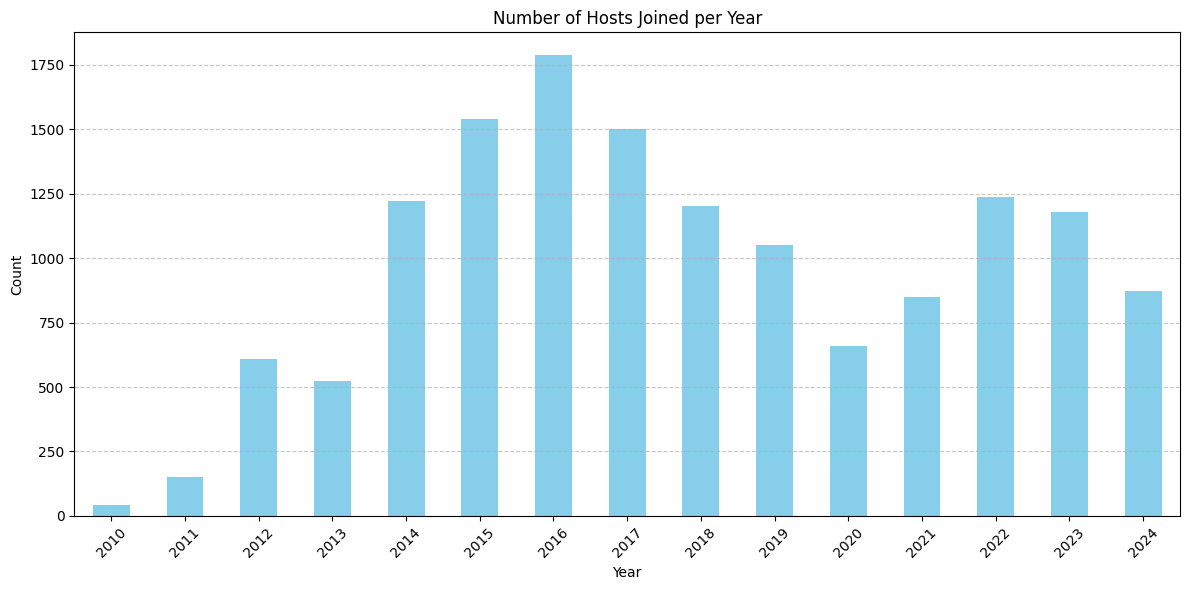

In [46]:
df_list['host_since'] = pd.to_datetime(df_list['host_since'])
year_counts = df_list['host_since'].dt.year.value_counts().sort_index()

plt.figure(figsize=(12, 6))
year_counts.plot(kind='bar', color='skyblue')
plt.title('Number of Hosts Joined per Year')
plt.xlabel('Year')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 2. Reviews

- Added a pre-computed sentiment column through sentiment analysis
- Added a column that maps review's listing ID to room type
- Dropped reviews without comment or invalid sentiment
- Reduced dataset to listing_id, date, comments, sentiment
- Explored the value distribution of multiple variables to decide on visualization approaches

In [47]:
# Reviews dataframe
df_reviews = pd.read_csv('reviews_complete_v2.csv', parse_dates=['date'], dtype={'comments': str})
df_reviews.dropna(subset=['comments', 'sentiment'], inplace=True)  # Remove reviews without comment or sentiment
df_reviews = df_reviews[['listing_id', 'date', 'comments', 'sentiment']]
df_reviews['month'] = df_reviews['date'].dt.to_period('M')  # Sparkcloud

# Associate review's listing_id with a room type
id_room_map = df_list.set_index('id')['room_type'].to_dict()
df_reviews['room_type'] = df_reviews['listing_id'].map(id_room_map)

df_reviews

,listing_id,date,comments,sentiment,month,room_type
0,208147,2015-07-03,Essa foi sem duvida a melhor experiencia que j...,-0.9321,2015-07,Private room
1,208147,2016-05-07,Notre séjour chez David et sa famille a été fa...,-0.3987,2016-05,Private room
2,208147,2016-07-10,That was our first and the most exciting exper...,0.9977,2016-07,Private room
3,208147,2016-08-11,"L'enchantement, la convivialité suprême,tout é...",0.0000,2016-08,Private room
4,208147,2016-08-25,Nuestra primera experiencia ha sido fantástica...,0.5815,2016-08,Private room
...,...,...,...,...,...,...
945282,1299310806226319071,2024-12-09,El apartamento perfecto. Muy limpio y moderno....,0.0000,2024-12,Entire home/apt
945283,1299875352888903077,2024-12-08,Pude permanecer poco tiempo en el apartamento ...,0.0000,2024-12,Entire home/apt
945284,1300567061227747165,2024-12-08,"Tive o prazer de ser a primeira hospede, pra m...",0.0000,2024-12,Entire home/apt
945285,1301672065067100759,2024-12-08,The apartment is beautiful with a very nice ba...,0.0000,2024-12,Entire home/apt


date
2011        67
2012       429
2013      1670
2014      4886
2015     13152
2016     26435
2017     47371
2018     71483
2019     98002
2020     34407
2021     58527
2022    158309
2023    201003
2024    222304
Name: count, dtype: int64


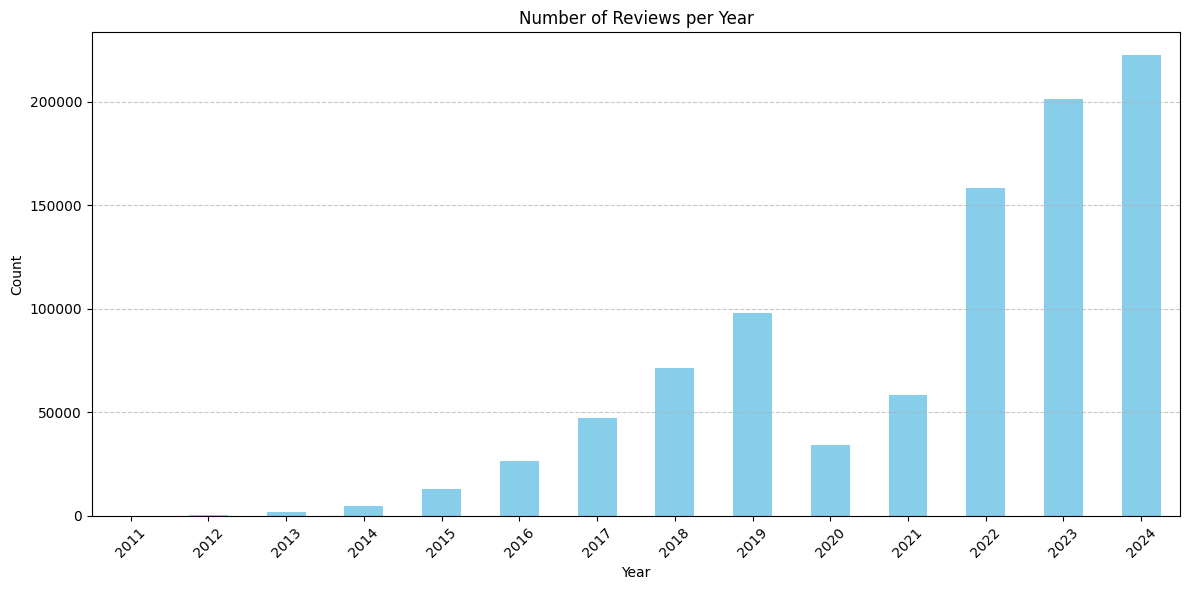

In [48]:
year_counts = df_reviews['date'].dt.year.value_counts().sort_index()
print(year_counts)

plt.figure(figsize=(12, 6))
year_counts.plot(kind='bar', color='skyblue')
plt.title('Number of Reviews per Year')
plt.xlabel('Year')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

date
1      42181
2      45495
3      59155
4      73594
5      89647
6      90388
7      99421
8     118610
9     110424
10    103124
11     64103
12     41903
Name: count, dtype: int64


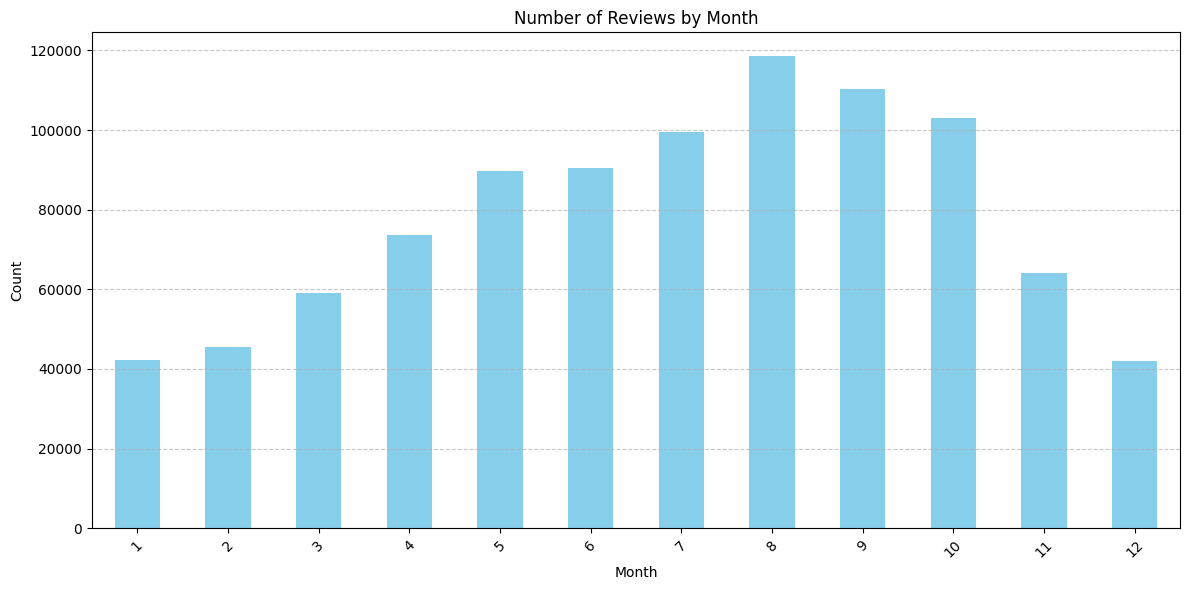

In [49]:
month_counts = df_reviews['date'].dt.month.value_counts().sort_index()
print(month_counts)

plt.figure(figsize=(12, 6))
month_counts.plot(kind='bar', color='skyblue')
plt.title('Number of Reviews by Month')
plt.xlabel('Month')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

room_type
Entire home/apt    830233
Hotel room            944
Private room       101164
Shared room          5704
Name: count, dtype: int64


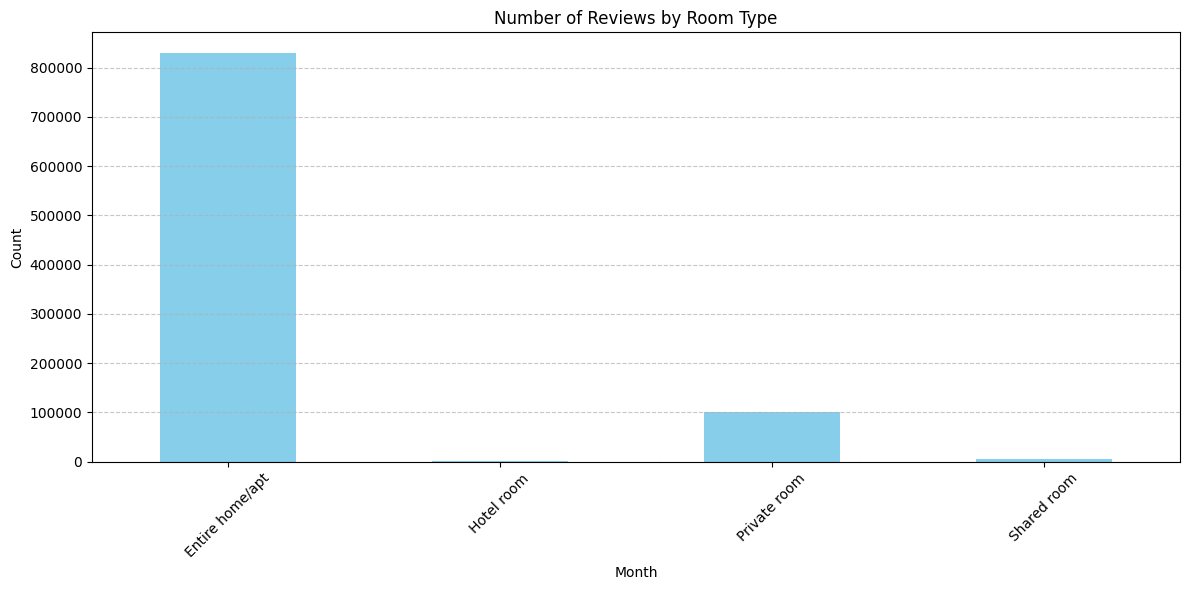

In [50]:
room_type_counts = df_reviews['room_type'].value_counts().sort_index()
print(room_type_counts)

plt.figure(figsize=(12, 6))
room_type_counts.plot(kind='bar', color='skyblue')
plt.title('Number of Reviews by Room Type')
plt.xlabel('Month')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 3. Monuments

- Reduced dataset to the most pertinent information (names and locations)
- Extracted portuguese name for the monuments through the label column

In [51]:
df_monuments = pd.read_csv('pontos-de-interesse-cultura-e-patrimonio-monumentos.csv',
                           quotechar="'",  # Use single quote as the quote character
                           delimiter=',',  # Comma is the actual delimiter
                           engine='python')  # Python engine handles this better)
df_monuments_red = df_monuments[['label', 'latitude', 'longitude']]
df_monuments_red['label'] = df_monuments_red['label'].apply(ast.literal_eval)  # str to dict
df_monuments_red['label'] = df_monuments_red['label'].apply(lambda x: x[0]['value'])  # Extract pt name
df_monuments_red

,label,latitude,longitude
0,Casa das Artes,41.156466,-8.643387
1,Pilares da Ponte Pênsil,41.140754,-8.609998
2,Torre dos Clérigos,41.145679,-8.614597
3,Arco ou Porta de Sant'Ana,41.142564,-8.613045
4,Palácio da Bolsa,41.141391,-8.615674
5,Casa de Almeida Garrett,41.143918,-8.617821
6,"Casa da Rua da Reboleira, nº 59",41.140221,-8.615706
7,"Casa da Rua da Reboleira, nº 55",41.140221,-8.615556
8,Casa do Beco dos Redemoinhos,41.142952,-8.610771
9,Casa do Infante / antiga Alfândega Régia,41.140762,-8.614537


### 4. Concert Halls

- Reduced dataset to the most pertinent information (names and locations)
- Extracted portuguese name for the concert halls through the label column

In [52]:
df_concert = pd.read_csv('pontos-de-interesse-cultura-e-patrimonio-salas-de-concerto.csv',
                         quotechar="'",  # Use single quote as the quote character
                         delimiter=',',  # Comma is the actual delimiter
                         engine='python')  # Python engine handles this better)
df_concert_red = df_concert[['label', 'latitude', 'longitude']]
df_concert_red['label'] = df_concert_red['label'].apply(ast.literal_eval)  # str to dict
df_concert_red['label'] = df_concert_red['label'].apply(lambda x: x[0]['value'])  # Extract pt name
df_concert_red

,label,latitude,longitude
0,Casa da Música,41.158592,-8.630383
1,Coliseu Porto Ageas,41.146906,-8.606236
2,Super Bock Arena - Pavilhão Rosa Mota,41.146898,-8.625888
3,Hard Club,41.141661,-8.614893
4,Centro de Cultura e Congressos - Ordem dos Méd...,41.172565,-8.610771
5,Maus Hábitos - Espaço de Intervenção Cultural,41.146703,-8.605746
6,Porta-Jazz,41.155125,-8.611306


### 5. University

- Custom dataset created with main elements of University of Porto, along with popular private universities located in Porto

In [53]:
df_uni = pd.read_csv('universities.csv', float_precision='high')
df_uni

,label,latitude,longitude
0,Faculdade de Letras,41.151089,-8.635195
1,Faculdade de Direito,41.152283,-8.618911
2,Faculdade de Engenharia,41.178362,-8.598420
3,Faculdade de Ciências,41.151792,-8.639184
4,Faculdade de Economia,41.175248,-8.601312
5,Faculdade de Arquitetura,41.150453,-8.638746
6,Faculdade de Belas Artes,41.145591,-8.603384
7,Faculdade de Desporto,41.178572,-8.602763
8,Faculdade de Medicina,41.179030,-8.602364
9,Instituto de Ciências Biomédicas Abel Salazar,41.147825,-8.628732


### 6. Transport Centers

- Custom dataset created with the major transportation hubs of Porto

In [54]:
df_transport = pd.read_csv('transport_centers.csv', float_precision='high')
df_transport

,label,latitude,longitude
0,Aeroporto Francisco Sá Carneiro,41.247403,-8.683239
1,São Bento Train Station,40.577543,-9.829875
2,Campanhã Train Station,41.148823,-8.588026
3,Campanhã Bus Station,41.152396,-8.583636


### 7. Metro

- Removed shapes of returning path [AR, BR, CR, DR, ER, FR] (same as going [AG, BG, CG, DG, EG, FG])
- Manually corrected the shape of line F (the dataset incorrectly stated it had the same shape as A)
- Sorted shapes by sequence for correct plotting in map
- Manually added the lines that pass through each stop (more informative in cases of shape overlap)

In [55]:
df_mshapes = pd.read_csv('metro_shapes.csv')
df_mshapes_red = df_mshapes[['shape_id', 'shape_pt_lat', 'shape_pt_lon', 'shape_pt_sequence']]
df_mshapes_red = df_mshapes_red[~df_mshapes_red['shape_id'].str.endswith('R')]  # Remove returning trajectories
df_mshapes_red = df_mshapes_red.sort_values(['shape_id', 'shape_pt_sequence'])  # Sort for correct plotting
df_mshapes_red

,shape_id,shape_pt_lat,shape_pt_lon,shape_pt_sequence
224,AG,41.171299,-8.542938,0
225,AG,41.175156,-8.541962,1
226,AG,41.179825,-8.543604,2
227,AG,41.185570,-8.545892,3
228,AG,41.183453,-8.553955,4
...,...,...,...,...
177,FG,41.165550,-8.636347,19
178,FG,41.172962,-8.641766,20
179,FG,41.177250,-8.646498,21
180,FG,41.182419,-8.652149,22


In [56]:
df_mstops = pd.read_csv('metro_stops.csv')
df_mstops_red = df_mstops[['stop_name', 'stop_lat', 'stop_lon', 'lines']]
df_mstops_red

,stop_name,stop_lat,stop_lon,lines
0,24 de Agosto,41.14880,-8.598349,"A,B,C,E,F"
1,Baguim,41.18557,-8.545892,F
2,Bolhão,41.14978,-8.605901,"A,B,C,E,F"
3,Brito Capelo,41.18391,-8.691469,A
4,Câmara Matosinhos,41.18070,-8.681227,A
...,...,...,...,...
80,Hospital São João,41.18326,-8.602240,D
81,Santo Ovídio,41.11555,-8.606555,D
82,Hospital Santos Silva,41.10576,-8.591075,D
83,Manuel Leão,41.11066,-8.599958,D


## Autoprofiler Visualizations

In [7]:
# Generated by AutoProfiler

import altair as alt 
binned_series = df_list["beds"].value_counts(bins=20, sort=False)

chart_data_binned = pd.DataFrame({
    "leftbin": binned_series.index.left, 
    "rightbin": binned_series.index.right, 
    "count": binned_series.values
})

# move leftmost bin edge up since pandas does not put edge at the min
chart_data_binned.loc[0, "leftbin"] = df_list["beds"].min()

quant_chart = alt.Chart(chart_data_binned).mark_bar(color="#fca5a5").encode(
    x = alt.X("leftbin", bin="binned", title="beds (binned)"),
    x2 = "rightbin",
    y = alt.Y("count")
).properties(
    width=500,
    height=200
)

quant_chart

alt.Chart(...)

In [8]:
# Generated by AutoProfiler

import altair as alt 
binned_series = df_list["review_scores_accuracy"].value_counts(bins=20, sort=False)

chart_data_binned = pd.DataFrame({
    "leftbin": binned_series.index.left, 
    "rightbin": binned_series.index.right, 
    "count": binned_series.values
})

# move leftmost bin edge up since pandas does not put edge at the min
chart_data_binned.loc[0, "leftbin"] = df_list["review_scores_accuracy"].min()

quant_chart = alt.Chart(chart_data_binned).mark_bar(color="#fca5a5").encode(
    x = alt.X("leftbin", bin="binned", title="review_scores_accuracy (binned)"),
    x2 = "rightbin",
    y = alt.Y("count")
).properties(
    width=500,
    height=200
)

quant_chart

alt.Chart(...)

## All transformations

In [ ]:
# df_Reviews dataframe
df_reviews = pd.read_csv('reviews_complete_v2.csv', parse_dates=['date'], dtype={'comments': str})
df_reviews.dropna(subset=['comments', 'sentiment'], inplace=True)  # Remove reviews without comment or sentiment
df_reviews = df_reviews[['listing_id', 'date', 'comments', 'sentiment']]
df_reviews['month'] = df_reviews['date'].dt.to_period('M')  # Sparkcloud

# Listings dataframe
df_list = pd.read_csv('listings_complete.csv', float_precision='high')
df_list = df_list[['id', 'host_id', 'host_since', 'host_response_time', 'host_acceptance_rate', 
                   'neighbourhood', 'latitude', 'longitude', 'room_type', 'accommodates', 
                   'bathrooms', 'beds', 'price', 'number_of_reviews', 'first_review', 
                   'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 
                   'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 
                   'review_scores_value', 'reviews_per_month']]

# Monuments dataframe
df_monuments = pd.read_csv('pontos-de-interesse-cultura-e-patrimonio-monumentos.csv',
                           quotechar="'",  # Use single quote as the quote character
                           delimiter=',',  # Comma is the actual delimiter
                           engine='python')  # Python engine handles this better)
df_monuments_red = df_monuments[['label', 'latitude', 'longitude']]
df_monuments_red['label'] = df_monuments_red['label'].apply(ast.literal_eval)  # str to dict
df_monuments_red['label'] = df_monuments_red['label'].apply(lambda x: x[0]['value'])  # Extract pt name

# Concert halls dataframe
df_concert = pd.read_csv('pontos-de-interesse-cultura-e-patrimonio-salas-de-concerto.csv',
                         quotechar="'",  # Use single quote as the quote character
                         delimiter=',',  # Comma is the actual delimiter
                         engine='python')  # Python engine handles this better)
df_concert_red = df_concert[['label', 'latitude', 'longitude']]
df_concert_red['label'] = df_concert_red['label'].apply(ast.literal_eval)  # str to dict
df_concert_red['label'] = df_concert_red['label'].apply(lambda x: x[0]['value'])  # Extract pt name

# Universities
df_uni = pd.read_csv('universities.csv', float_precision='high')

# Transport Centers
df_transport = pd.read_csv('transport_centers.csv', float_precision='high')

# Metro line shapes
df_mshapes = pd.read_csv('metro_shapes.csv')
df_mshapes_red = df_mshapes[['shape_id', 'shape_pt_lat', 'shape_pt_lon', 'shape_pt_sequence']]
df_mshapes_red = df_mshapes_red[~df_mshapes_red['shape_id'].str.endswith('R')]  # Remove returning trajectories
df_mshapes_red = df_mshapes_red.sort_values(['shape_id', 'shape_pt_sequence'])  # Sort for correct plotting

# Metro stops
df_mstops = pd.read_csv('metro_stops.csv')
df_mstops_red = df_mstops[['stop_name', 'stop_lat', 'stop_lon', 'lines']]

# Convert price strings to float (e.g. $3,900.00 -> 3900.00)
df_list['price'] = df_list['price'].str.replace('$', '', regex=False)\
                                   .str.replace(',', '', regex=False)\
                                   .astype(float)

# Associate review's listing_id with a room type
id_room_map = df_list.set_index('id')['room_type'].to_dict()
df_reviews['room_type'] = df_reviews['listing_id'].map(id_room_map)